# Learning a DES-footprint map generator from Rafael's simulations

This notebook accompanies [the teaching note](gptg_simulations.pdf). We implement the point-transformed Gaussian method of [Kunhao Zhong and coauthors](https://arxiv.org/abs/2411.04759), fit an initial model to 32 supplied maps, save 64 new four-bin maps with Gaussian shape noise, and measure second- and third-order apertures. **This pilot is not a validated DES covariance model.**

**Thanks to Kunhao Zhong and coauthors for the method, Rafael Gomes for the simulation maps, and the ducc0/HEALPix developers for the transforms and geometry.** This is our implementation and fit, not a supplied author calibration.

The default cells use compact records committed under `tests/gptg_pilot/`. They do not process the full archive. Optional generation and measurement commands appear at the end. Raw generated maps stay under the ignored `chains/gptg_method/maps/` directory.

## How to use this notebook

The note and this notebook form one account. Read the small algebra examples
first, redraw the four frozen figures, and only then analyze saved simulation
measurements. **Running the ordinary teaching cells does not start map generation
or TreeCorr.** Those production programs are in `../../scripts/` and the HPC
submission instructions are in the project README.

The later sections expose the actual analysis calculations as named Python
functions. Their arguments replace command-line flags. Read the comments before
calling one: some need downloaded maps, some need completed HPC measurements,
and GPU checks need MLX on an Apple machine. Outputs go to `chains/`; the frozen
figure inputs in this note are retained so its illustrations remain reproducible.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import os
# Set these before importing numerical libraries. ducc0 separately gets
# nthreads=4 in the map script; BLAS never gets four workers.
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '4'
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import yaml
from IPython.display import Image, display

# Find this project whether Jupyter starts here or at the project root.
PROJECT = Path.cwd().resolve()
while not (PROJECT / 'EXAMPLE_COVARIANCE_PME.ipynb').exists():
    if PROJECT == PROJECT.parent:
        raise FileNotFoundError('Start this notebook within projects/des_3pcf.')
    PROJECT = PROJECT.parent
NOTE = PROJECT / 'notes' / 'gptg_simulations'
RECORDS = PROJECT / 'tests' / 'gptg_pilot'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

# Production modules live in scripts; covariance algebra is shared with the Eifler note.
import sys
sys.path.insert(0, str(PROJECT / "scripts"))
sys.path.insert(0, str(PROJECT / "notes/covariance_from_simulations"))


## 1. Inspect the calibration before using it

The transform acts on **convergence**, not separately on the two shear components. Our available input maps contain shear. We therefore fit a *masked, smoothed, noisy reconstruction proxy* as an initial approximation. This distinction is one reason a small quantile-fit residual does not validate the resulting sky model.

Read the recorded input selection, noise amplitudes and transformation family. The bin-two fit uses the paper's four-parameter restriction because an unrestricted initial fit turned over in a tail. Parameters near their fitting bounds also deserve attention.

In [2]:
calibration = yaml.safe_load((RECORDS / 'calibration.yaml').read_text())
generation = yaml.safe_load((RECORDS / 'generation.yaml').read_text())
print('Calibration maps:', len(calibration['source_files']))
print('Generated maps:', generation['count'])
print('NSIDE and maximum multipole:', calibration['nside'], calibration['lmax'])
print('Per-component pixel noise:', calibration['noise_sigma_per_component'])
for source, family in enumerate(calibration['fitted_family'], start=1):
    print('Source', source, ':', family)
print('Parameters are a1, a2, b, x0, t:')
print(np.asarray(calibration['point_parameters_a1_a2_b_x0_t']))

Calibration maps: 32
Generated maps: 64
NSIDE and maximum multipole: 512 1024
Per-component pixel noise: [0.03544957212835064, 0.03845571849948187, 0.038129787831707534, 0.04684877382544602]
Source 1 : five-parameter
Source 2 : four-parameter; b fixed to zero for global monotonicity
Source 3 : five-parameter
Source 4 : five-parameter
Parameters are a1, a2, b, x0, t:
[[ 2.37551585e-01  2.13293612e-01  9.99996434e-01  1.25883628e+00
   4.00000000e+00]
 [ 2.68977167e-02  5.00000002e-03  0.00000000e+00  2.76947383e+00
   4.81012632e-01]
 [ 1.31889354e-02  1.26374845e-02  2.60573386e-06  1.26083202e+00
   4.00000000e+00]
 [ 2.19034250e-01  1.95423544e-01  1.00000000e+00 -3.00000000e+00
   2.00000000e-01]]


## 2. Why a nonlinear point transform also changes correlations

Take two unit Gaussian variables with correlation $\rho$. For a simple centered lognormal transform, define

$$f_i(g)=e^{a_i g-a_i^2/2}-1.$$

The Gaussian exponential identity gives

$$\mathbb E[e^{a_i g_1+a_j g_2}]
=\exp\left[\frac12(a_i^2+a_j^2+2a_ia_j\rho)\right].$$

Multiplying by the two normalization factors cancels $a_i^2/2$ and $a_j^2/2$, leaving $e^{a_ia_j\rho}$. Expanding the product of the two centered transforms then gives

$$\mathbb E[f_i(g_1)f_j(g_2)]
=e^{a_ia_j\rho}-1-1+1=e^{a_ia_j\rho}-1.$$

Thus a desired output correlation is generally **not** the Gaussian input correlation. For the more flexible fitted function, the code evaluates and inverts this relation numerically through Hermite coefficients. The note derives each step. The small example below shows the change even in the simpler analytic case.

In [3]:
a = 0.5
rho = 0.6
# Divide by the lognormal variance to obtain its correlation coefficient.
output_correlation = np.expm1(a*a*rho) / np.expm1(a*a)
# Invert the same relation, recovering the required Gaussian correlation.
recovered = np.log1p(output_correlation*np.expm1(a*a)) / (a*a)
print('Gaussian correlation:', rho)
print('Transformed correlation:', output_correlation)
np.testing.assert_allclose(recovered, rho, atol=1.e-14)
print('Inversion recovers:', recovered)

Gaussian correlation: 0.6
Transformed correlation: 0.5697878894627386
Inversion recovers: 0.6000000000000001


## 3. A footprint index is a sky address

A saved map has shape `(4, 2, 369190)`: four source bins, two shear components and retained pixels. Entry `map[i,c,j]` belongs to full-sky pixel `indices_512[j]`. The last axis is not a rectangular image.

The pilot uses the RING ordering supported by the earlier geometric footprint check. A second-component sign diagnostic favors the current convention, but producer confirmation is still needed for sign-sensitive third moments. Generating convergence on the sphere, converting it to shear, and only then selecting footprint pixels retains the intended large-scale spatial correlations.

In [4]:
number_of_pixels = generation['shape'][-1]
bytes_per_map = 4 * 2 * number_of_pixels * 8  # float64 payload
print('Payload per map [MB]:', bytes_per_map/1.e6)
print('64-map payload [GB]:', 64*bytes_per_map/1.e9)
print('10000-map payload [GB]:', 10000*bytes_per_map/1.e9)
timing = np.loadtxt(fname=RECORDS / 'generation_timing.txt')
print('Median generation/save/aperture seconds:', np.median(timing, axis=0))
print('Median total seconds:', np.median(timing.sum(axis=1)))

Payload per map [MB]: 23.62816
64-map payload [GB]: 1.51220224
10000-map payload [GB]: 236.2816
Median generation/save/aperture seconds: [4.25585071e+00 4.22324997e-03 6.79079152e-03]
Median total seconds: 4.267709020990878


## 4. Correct a noisy aperture square and cube

A filtered aperture is $A=s+n$, where $s$ is fixed while we average over noise. Assume $\mathbb E[n]=0$, $\mathbb E[n^2]=v$ and zero third noise moment. Expanding the square gives

$$A^2=s^2+2sn+n^2.$$

Averaging each term gives

$$\mathbb E[A^2\mid s]=s^2+2s(0)+v=s^2+v.$$

Subtract the known variance:

$$\mathbb E[A^2-v\mid s]=s^2.$$

For the cube, multiply the three factors before averaging:

$$A^3=s^3+3s^2n+3sn^2+n^3.$$

Therefore

$$\mathbb E[A^3\mid s]=s^3+3s^2(0)+3sv+0=s^3+3sv.$$

The signal is unknown, but $\mathbb E[A\mid s]=s$. Multiplying that identity by $3v$ and subtracting yields

$$\mathbb E[A^3-3vA\mid s]=s^3+3sv-3vs=s^3.$$

**This aperture correction is different from correcting the square of a noisy covariance matrix in Eifler's expansion.** Neither operation removes the random scatter of a noisy observation.

In [5]:
from scipy.special import roots_hermitenorm

# Gaussian quadrature integrates the low-degree polynomial exactly,
# making a coefficient/sign mistake visible without Monte Carlo noise.
nodes, weights = roots_hermitenorm(n=12)
weights = weights / np.sqrt(2*np.pi)
signal = 0.2
noise_variance = 0.07
aperture = signal + np.sqrt(noise_variance)*nodes
raw_second = weights @ aperture**2
corrected_second = weights @ (aperture**2-noise_variance)
raw_third = weights @ aperture**3
corrected_third = weights @ (aperture**3-3*noise_variance*aperture)
print('Square: raw, corrected, target:', raw_second, corrected_second, signal**2)
print('Cube: raw, corrected, target:', raw_third, corrected_third, signal**3)
np.testing.assert_allclose(corrected_second, signal**2, atol=1.e-14)
np.testing.assert_allclose(corrected_third, signal**3, atol=1.e-14)

Square: raw, corrected, target: 0.11000000000000001 0.04000000000000002 0.04000000000000001
Cube: raw, corrected, target: 0.05000000000000002 0.008000000000000007 0.008000000000000002


## 5. Carry the correction to mixed source bins

There are three ways to pair two noise factors in a cubic product. If $V_{ij}$ is their covariance, the corrected product is

$$T_{ijk}=A_iA_jA_k-V_{ij}A_k-V_{ik}A_j-V_{jk}A_i.$$

The note expands all eight terms of the original product and cancels the three extra expectations. In our initial model, different source bins have independent noise. For `(1,1,2)`, only $V_{11}A_2$ remains; for `(1,2,3)`, no pair subtraction remains. The same-bin case has all three pairings and reduces to the factor of three above.

The filter noise is calculated from **squared pixel weights**, not fitted from the measured cube. We retain one variance per source, radius and center. The next cells inspect the resulting raw/corrected measurements for all 60 tomographic rows. For Rafael's maps, the assumed pixel-noise prescription is approximate; these corrections do not establish his actual estimator.

In [6]:
rows = np.loadtxt(fname=RECORDS / 'tomographic_rows.txt', dtype=int)
raw = np.loadtxt(fname=RECORDS / 'generated_tomographic_raw.txt')
corrected = np.loadtxt(fname=RECORDS / 'generated_tomographic_corrected.txt')
filter_variance = np.loadtxt(fname=RECORDS / 'aperture_noise_variance.txt')
print('Rows: order, radius, source i, source j, source k:')
print(rows[:3])
print('Maps by measurements:', raw.shape)
print('Filter-noise rows by centers:', filter_variance.shape)
# Row 10 is the first cubic row: source 1 three times, at 30 arcminutes.
row = 10
print('Selected cubic row:', rows[row])
print('Mean raw cube:', raw[:, row].mean())
print('Mean corrected cube:', corrected[:, row].mean())
# Distinct bins have no correction under the stipulated noise model.
distinct = (rows[:,0] == 3) & (rows[:,2] < rows[:,3]) & (rows[:,3] < rows[:,4])
np.testing.assert_array_equal(raw[:, distinct], corrected[:, distinct])

Rows: order, radius, source i, source j, source k:
[[ 2 30  1  1  0]
 [ 2 30  1  2  0]
 [ 2 30  1  3  0]]
Maps by measurements: (64, 60)
Filter-noise rows by centers: (8, 64)
Selected cubic row: [ 3 30  1  1  1]
Mean raw cube: 4.1467049172298355e-10
Mean corrected cube: 3.630943045092821e-10


## 6. Test the maps after all transformations

Fitting the central proxy quantiles is only a starting step. We must remeasure spectra, distributions, means and covariance after applying the same footprint, noise and measurement. The figures below come from the saved measurements, and their adjacent plot scripts redraw from text alone.

The spectra compare 64 generated maps with the 32 calibration maps. The covariance comparison uses the same **16 raw same-source moments** as the complete 15,997-vector Rafael diagnostic. It does not silently switch to the 60 corrected rows. The starting fit reused part of the reference ensemble, so these are consistency diagnostics, not independent validation p-values.

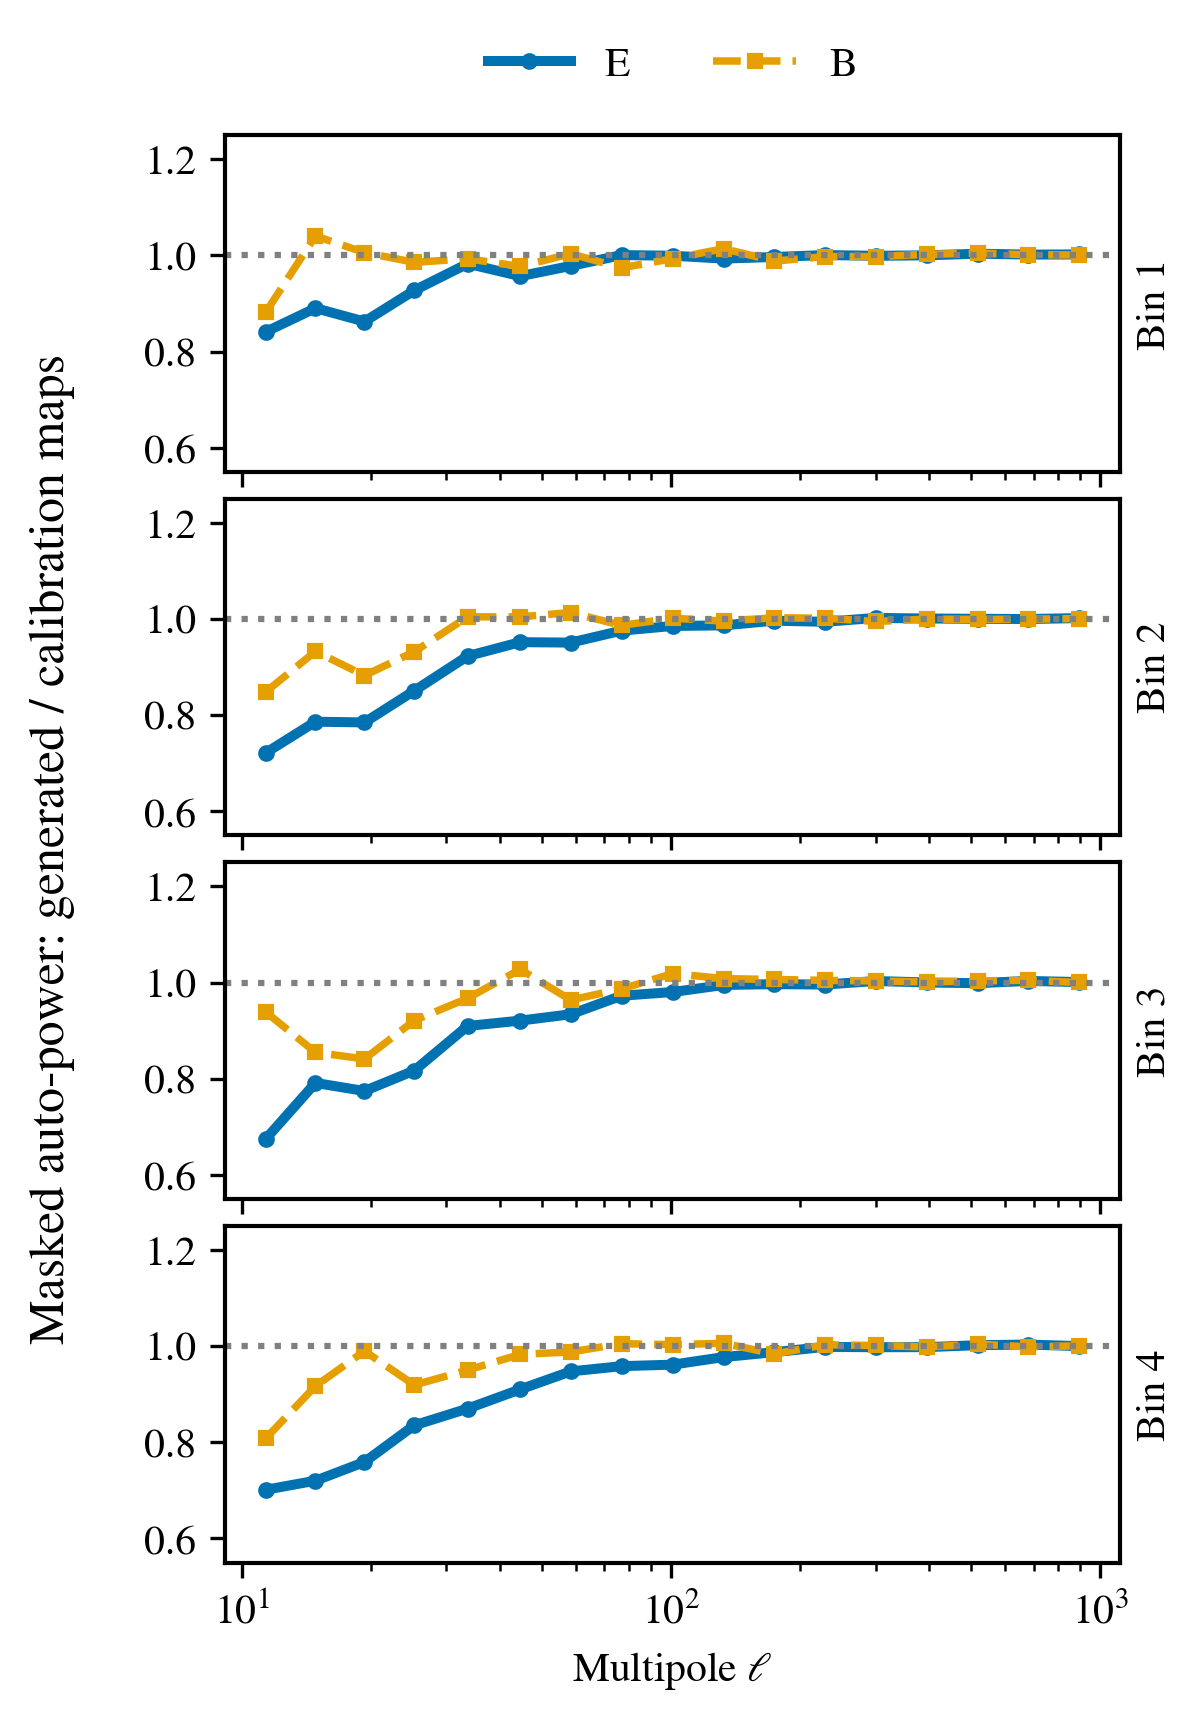

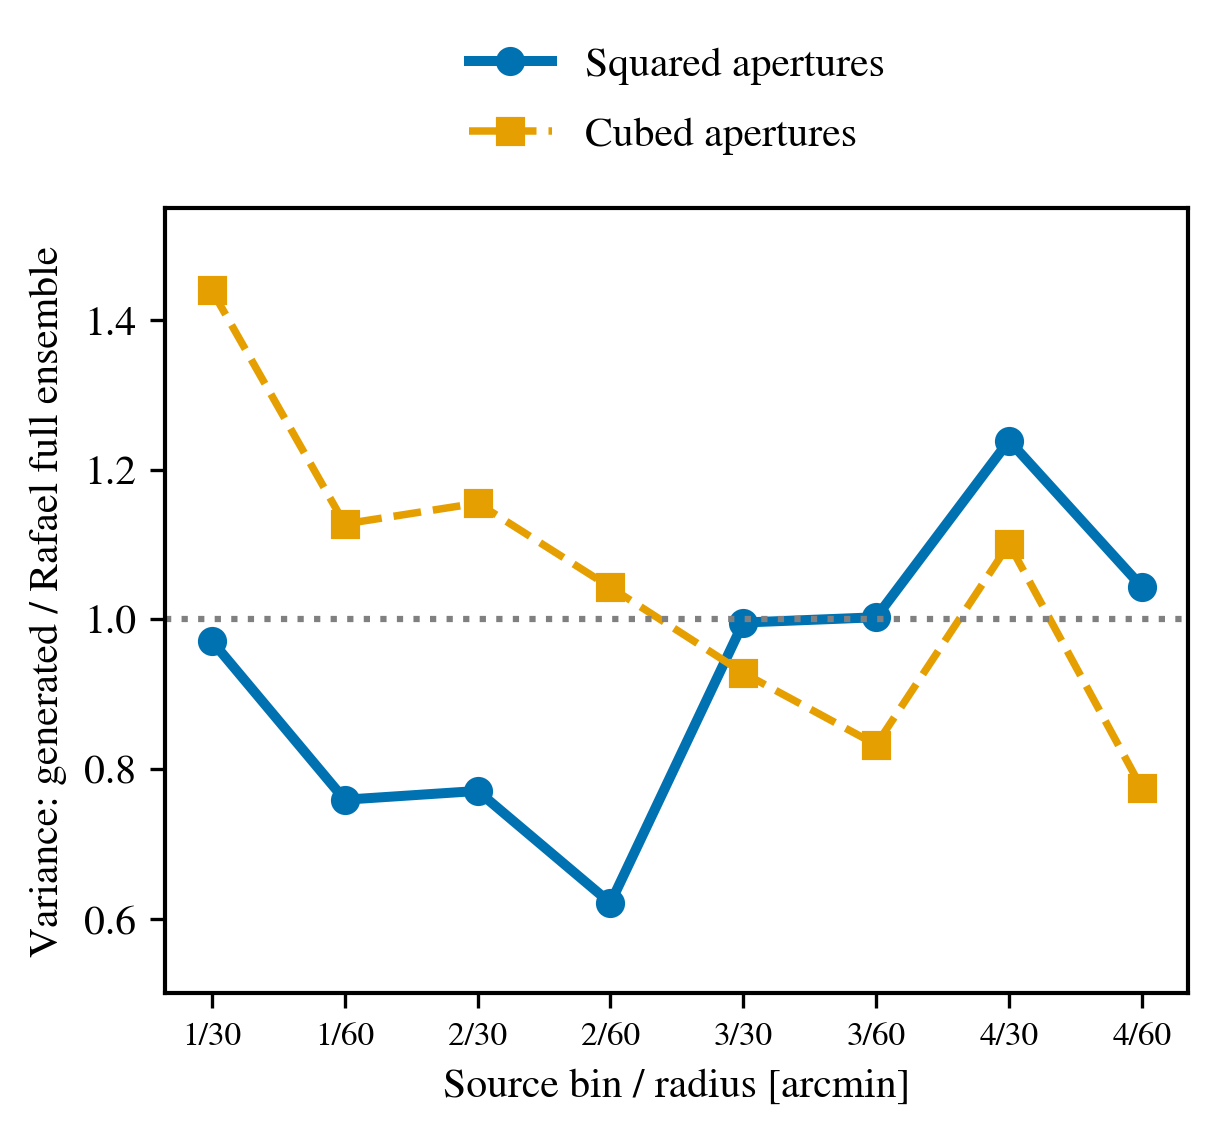

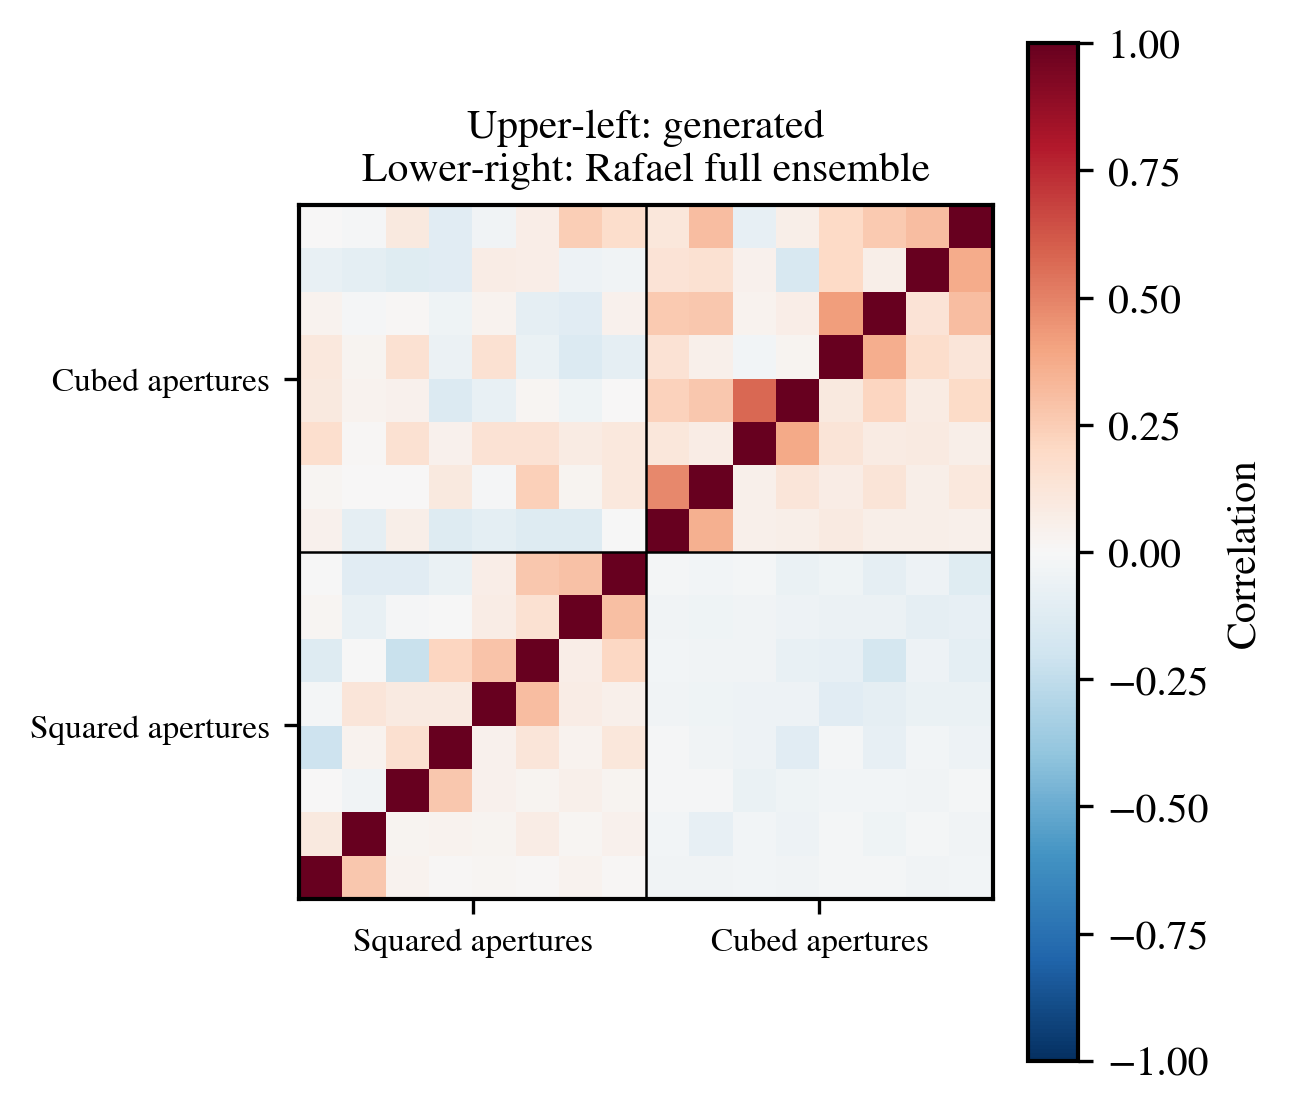

Variance-ratio range: 0.6207341560973392 1.4397128153454377
Largest absolute correlation difference: 0.332108476048442
Gaussian benchmark for 64-map variance scatter: 0.1781741612749496


In [7]:
for figure in ('spectra', 'variance', 'correlation'):
    display(Image(filename=str(NOTE / 'plots' / figure / f'{figure}.png'), width=650))

reference = np.loadtxt(
    fname=PROJECT / 'tests/covariance_map_comparison/all_maps_covariance.txt',
)
generated = np.loadtxt(fname=RECORDS / 'generated_covariance.txt')
ratio = np.diag(generated)/np.diag(reference)
reference_scale = np.sqrt(np.diag(reference))
generated_scale = np.sqrt(np.diag(generated))
reference_correlation = reference/reference_scale[:,None]/reference_scale[None,:]
generated_correlation = generated/generated_scale[:,None]/generated_scale[None,:]
print('Variance-ratio range:', ratio.min(), ratio.max())
print('Largest absolute correlation difference:',
      np.max(np.abs(generated_correlation-reference_correlation)))
print('Gaussian benchmark for 64-map variance scatter:', np.sqrt(2/63))

## 7. What sixth order does on a measured-vector population

We need known truth to test algebra. The continuous map model does not provide an exact covariance for these measured statistics. Instead, define a discrete population consisting of all 64 saved vectors, each with probability $1/64$. Select four joint second-/third-order rows. Its covariance uses denominator **64**, because the list defines the whole population. Covariances estimated from independent samples drawn from it use **$N-1$**.

Each experiment chooses 128 or 512 list members independently *with replacement*. We repeated this 8,192 times. These are independent experiments conditional on the list, **not new independent physical skies**. A fixed positive reference is chosen before resampling. The error compares estimated precision with the exact inverse of this specified population covariance.

The distinct-pair method needs independence and suitable finite moments, but not a Gaussian distribution. The Wishart formulas are tested deliberately even though these measurements are not Gaussian. Unbiasedness for a truncated polynomial does not imply unbiasedness for the full inverse or its inverse covariance.

Exactly defined discrete-population covariance:
[[ 1.          0.0201648   0.0467967  -0.07676721]
 [ 0.0201648   1.         -0.12952458 -0.04906478]
 [ 0.0467967  -0.12952458  1.          0.13601114]
 [-0.07676721 -0.04906478  0.13601114  1.        ]]
128 draws, distinct-pair RMS at orders 2,4,6: [0.19427558 0.22626533 0.26736764]
512 draws, distinct-pair RMS at orders 2,4,6: [0.15818393 0.11648588 0.13001479]


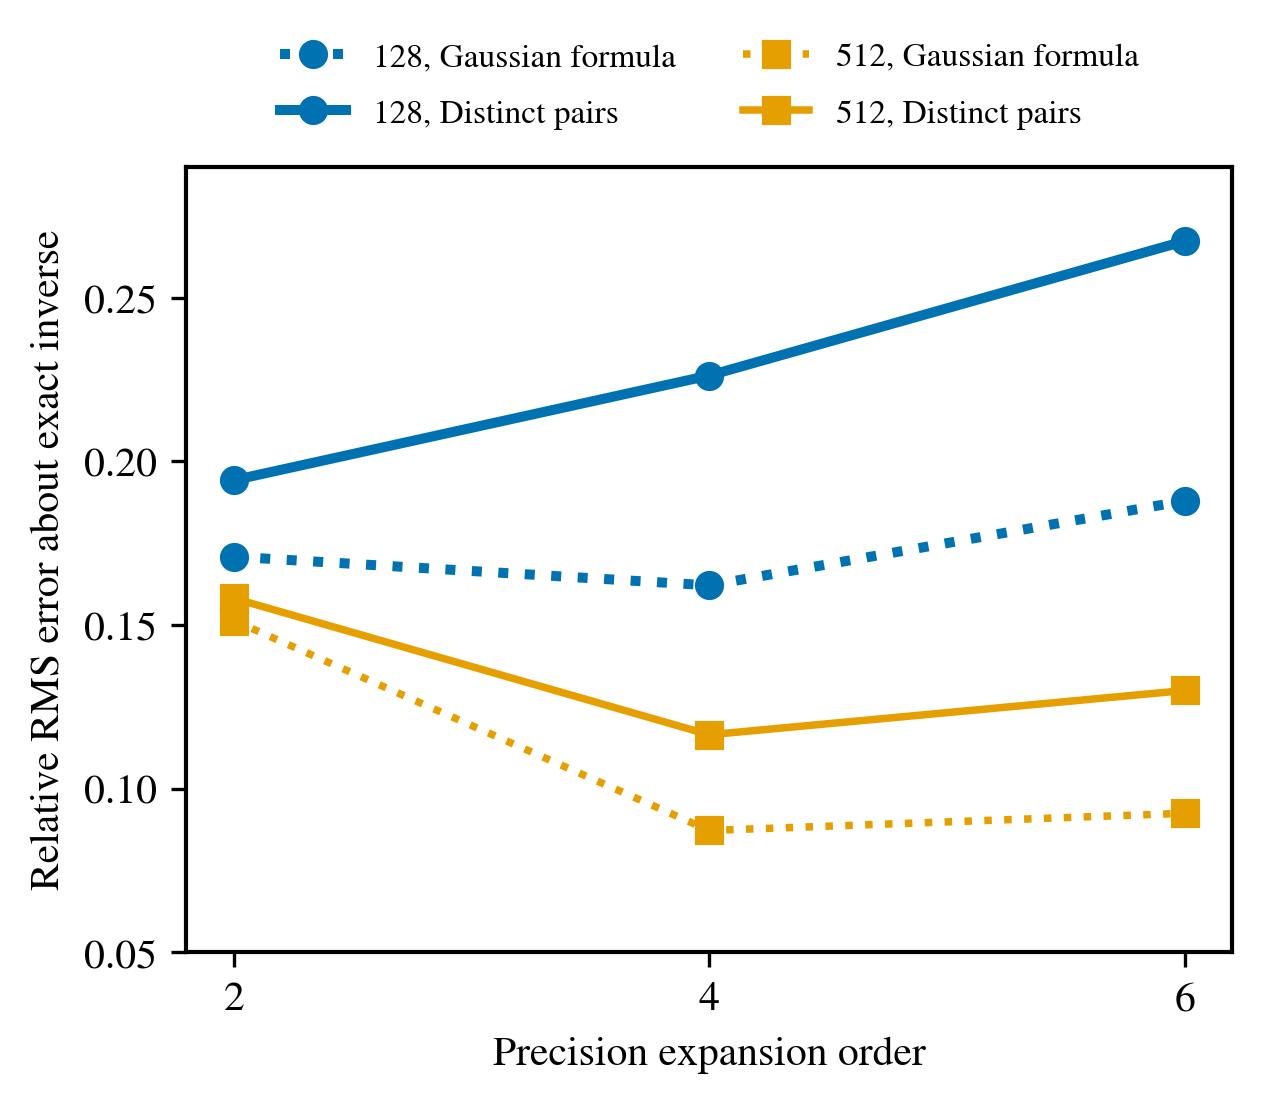

In [8]:
population = np.loadtxt(fname=RECORDS / 'measurement_population.txt')[:, [0,6,8,14]]
# Fix the unit conversion using the stipulated full population.
standardized = (population-population.mean(axis=0))/population.std(axis=0)
true_covariance = standardized.T @ standardized / len(standardized)
print('Exactly defined discrete-population covariance:')
print(true_covariance)
summary = np.loadtxt(fname=RECORDS / 'gptg_empirical_summary.txt')
# Column 4 is relative RMS error about the exact inverse. Column 3
# instead measures error about the finite polynomial target.
for count in (128,512):
    selected = summary[(summary[:,0] == count) & (summary[:,1] >= 3)]
    print(count, 'draws, distinct-pair RMS at orders 2,4,6:', selected[:,4])
display(Image(filename=str(NOTE / 'plots/precision/precision.png'), width=650))

More draws reduce scatter. In this experiment, 512 draws make fourth order useful, but sixth order still has higher RMS error. This is evidence against choosing the largest available order by default. Neither resampling nor an arbitrarily large generator ensemble removes uncertainty or missing physics in the calibration.

## 9. What to improve before using thousands of additional mocks

The immediate physical work is a forward calibration of the masked power and reconstructed distributions, a checked noise/weight model, confirmation of shear conventions, convergence with harmonic range, and measurement of the intended published estimator. The existing coarse aperture comparisons are useful diagnostics, not that final matching. Parameter uncertainty in the fitted generator also matters: infinitely many draws from an uncertain model do not yield infinitely precise knowledge of the N-body covariance.

The separate [precision-expansion note](../covariance_from_simulations/covariance_from_simulations.pdf) contains the full second-to-sixth-order algebra and Gaussian/lognormal tests. The [Rafael comparison](../covariance_comparison/covariance_comparison.pdf) compares the same complete supplied ensemble with the same complete ensemble, and separately examines matched released DES bins.

## 10. Float32 files and independent validation

The 64-map rounding test compares float32 storage with float64 storage while keeping arithmetic in float64. New ensemble files use float32 (about 177 GB for 15,000 maps). The small original pilot remains float64 as a precision reference.

The larger run has **10,000 comparison maps plus 5,000 new validation maps**. It is still running; the cells below do not claim its results. All comparison maps enter both the direct and Eifler estimates. Validation does not choose the reference or expansion order.

For a fixed positive precision, use the score

$$J(\Psi)=\operatorname{tr}(\Psi C_*)-\log\det\Psi.$$

Its expectation is minimized at the true inverse covariance even for non-Gaussian vectors with finite covariance. The note proves this by diagonalizing $C_*^{1/2}\Psi C_*^{1/2}$. On independent validation data, replace $C_*$ by its unbiased sample covariance **without inverting it**. Score differences therefore do not require the direct inverse to be truth. The next small known-covariance example checks the target numerically.

In [9]:
print((RECORDS / 'float32_storage_check.txt').read_text())
true_covariance = np.array([[2., .3], [.3, 1.]])
true_precision = np.linalg.solve(a=true_covariance, b=np.eye(2))
true_score = np.trace(true_precision @ true_covariance)
true_score -= np.linalg.slogdet(true_precision)[1]
for factor in (0.5, 1., 1.5):
    candidate = factor*true_precision
    score = np.trace(candidate @ true_covariance)
    score -= np.linalg.slogdet(candidate)[1]
    expected_difference = 2*(factor-1.-np.log(factor))
    np.testing.assert_allclose(score-true_score, expected_difference, atol=1.e-14)
    print('Precision multiplier, excess expected score:', factor, score-true_score)
print('The minimum occurs at the known true precision in this worked example.')

max_absolute_shear_rounding 8.57983639690473865e-09
max_moment_change_in_its_single_map_standard_deviation 1.19411115907004286e-07
max_joint_covariance_weighted_vector_change 2.56353941029503208e-07
max_fractional_variance_change 1.49890324596668734e-08
max_relative_covariance_eigendirection_change 5.25167417506345957e-08
max_relative_precision_eigendirection_change 5.25167390685865598e-08

Precision multiplier, excess expected score: 0.5 0.3862943611198908
Precision multiplier, excess expected score: 1.0 0.0
Precision multiplier, excess expected score: 1.5 0.18906978378367123
The minimum occurs at the known true precision in this worked example.


## Redraw the figures from their numerical records

These four cells read small text tables, not maps. The spectrum plot compares
the masked observables; the variance plot compares diagonal covariance entries;
the correlation plot removes units; the precision plot tests expansion order.
A match in one plot does not imply a match in the others. In particular, matching
variance alone does not establish a correct inverse covariance.

Each cell states its input directory and saves the same PDF/PNG used by the note.
The plotting arithmetic is here so the student can inspect each normalization.


### Spectra comparison

Read the text records first, form the plotted statistic, then label its units.

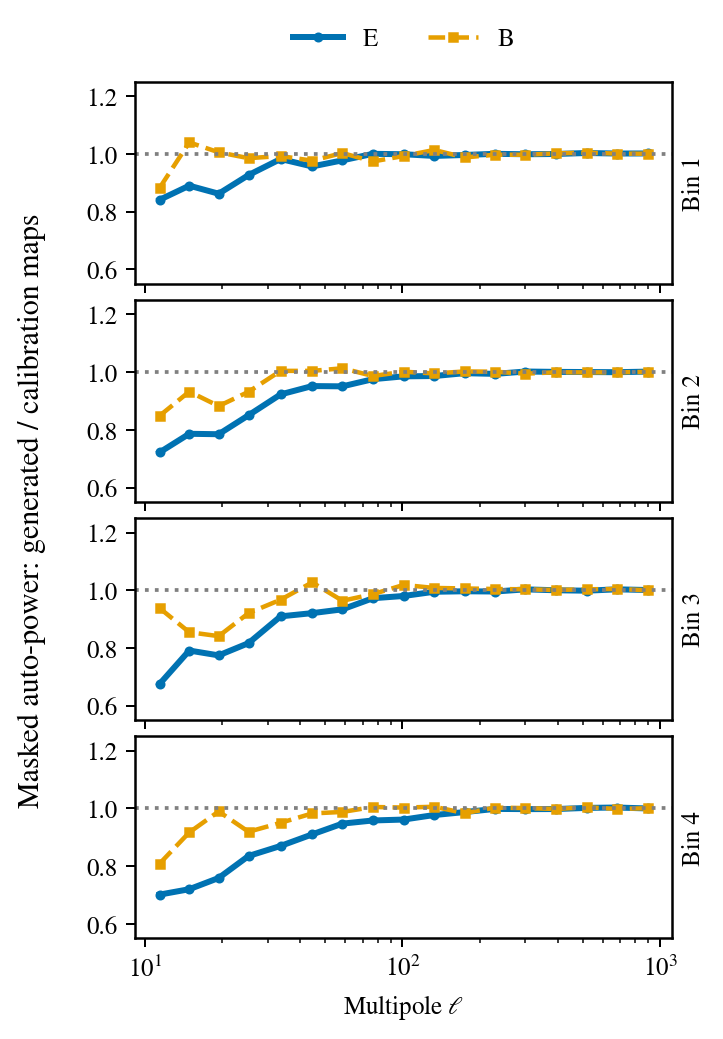

In [10]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/spectra"

data = np.loadtxt(fname=folder / 'data.txt')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(4.2, 6.1), sharex=True)
fig.subplots_adjust(hspace=.08, top=.89, left=.18, right=.89)
for source, ax in enumerate(axes):
    for parity in (0, 1):
        rows = data[(data[:, 2] == source) & (data[:, 3] == source)
                    & (data[:, 4] == parity)]
        ell = np.sqrt(rows[:, 0]*rows[:, 1])
        ax.plot(ell, rows[:, 6]/rows[:, 5], color=['#0072B2','#E69F00'][parity],
                linewidth=[2.4,1.8][parity], marker=['o','s'][parity],
                markersize=3, linestyle=['-','--'][parity], label=['E','B'][parity])
    ax.axhline(y=1., color='gray', linestyle=':')
    ax.set_ylim(bottom=.55, top=1.25)
    ax.set_xscale('log')
    ax.set_ylabel(f'Bin {source+1}')
    ax.yaxis.set_label_position('right')
legend = axes[0].legend(loc='lower center', bbox_to_anchor=(.5, 1.04),
                       ncol=2, frameon=False)
fig.supylabel('Masked auto-power: generated / calibration maps', x=.025)
axes[-1].set_xlabel(r'Multipole $\ell$')
fig.canvas.draw()
assert not legend.get_window_extent().overlaps(axes[0].get_window_extent())
NAME = 'spectra.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


### Variance comparison

Read the text records first, form the plotted statistic, then label its units.

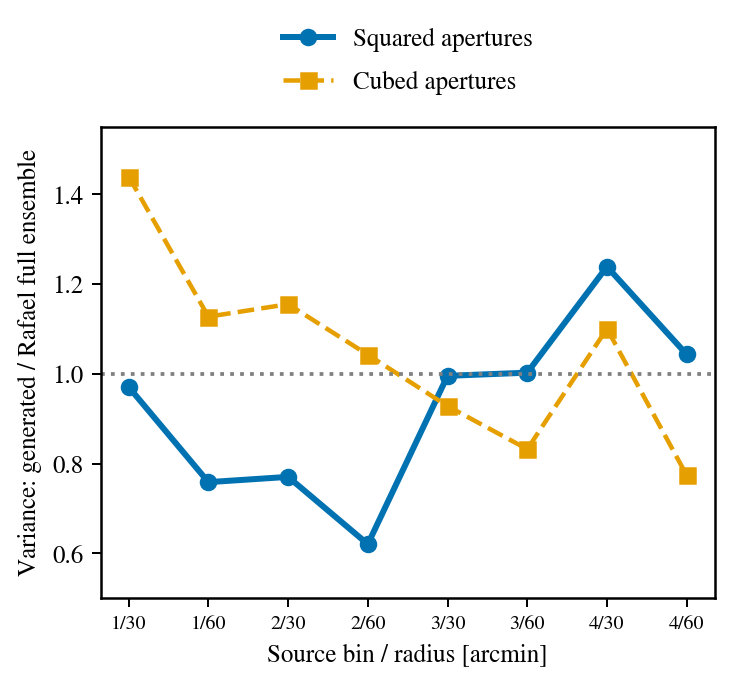

In [11]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/variance"

reference = np.loadtxt(fname=folder / 'reference.txt')
generated = np.loadtxt(fname=folder / 'generated.txt')
ratio = np.diag(generated) / np.diag(reference)
fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.plot(np.arange(8), ratio[:8], color='#0072B2', marker='o',
        linewidth=2.4, label='Squared apertures')
ax.plot(np.arange(8), ratio[8:], color='#E69F00', marker='s',
        linewidth=1.8, linestyle='--', label='Cubed apertures')
ax.axhline(y=1., color='gray', linestyle=':')
ax.set_xticks(ticks=np.arange(8), labels=['1/30','1/60','2/30','2/60',
                                       '3/30','3/60','4/30','4/60'])
ax.tick_params(axis='x', labelsize=8)
ax.set_xlabel('Source bin / radius [arcmin]')
ax.set_ylabel('Variance: generated / Rafael full ensemble')
ax.set_ylim(bottom=.5, top=1.55)
legend = ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.02), frameon=False)
fig.canvas.draw()
assert not legend.get_window_extent().overlaps(ax.get_window_extent())
NAME = 'variance.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


### Correlation comparison

Read the text records first, form the plotted statistic, then label its units.

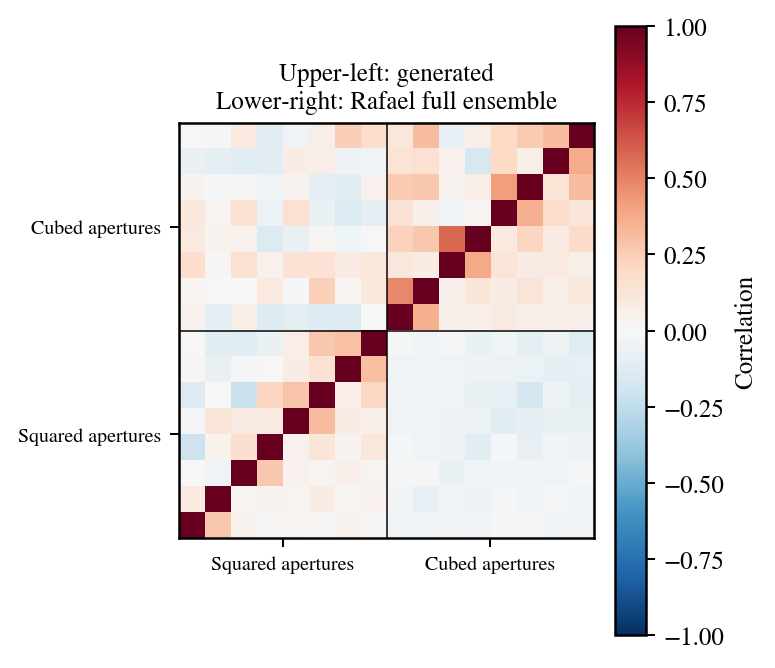

In [12]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/correlation"

reference = np.loadtxt(fname=folder / 'reference.txt')
generated = np.loadtxt(fname=folder / 'generated.txt')
old_scale = np.sqrt(np.diag(reference))
new_scale = np.sqrt(np.diag(generated))
old = reference / old_scale[:, None] / old_scale[None, :]
new = generated / new_scale[:, None] / new_scale[None, :]
# With origin=lower, row>=column is the displayed upper-left triangle.
# Generated maps occupy that half; the full supplied ensemble is lower-right.
combined = np.where(np.tril(np.ones((16, 16), dtype=bool)), new, old)
fig, ax = plt.subplots(figsize=(4.2, 3.6), constrained_layout=True)
artist = ax.imshow(X=combined, origin='lower', cmap='RdBu_r', vmin=-1., vmax=1.)
fig.colorbar(mappable=artist, ax=ax, label='Correlation')
ax.axhline(y=7.5, color='black', linewidth=.6)
ax.axvline(x=7.5, color='black', linewidth=.6)
ax.set_xticks(ticks=[3.5, 11.5], labels=['Squared apertures', 'Cubed apertures'])
ax.set_yticks(ticks=[3.5, 11.5], labels=['Squared apertures', 'Cubed apertures'])
ax.tick_params(axis='both', labelsize=8)
ax.set_title('Upper-left: generated\nLower-right: Rafael full ensemble', fontsize=10)
NAME = 'correlation.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


### Precision comparison

Read the text records first, form the plotted statistic, then label its units.

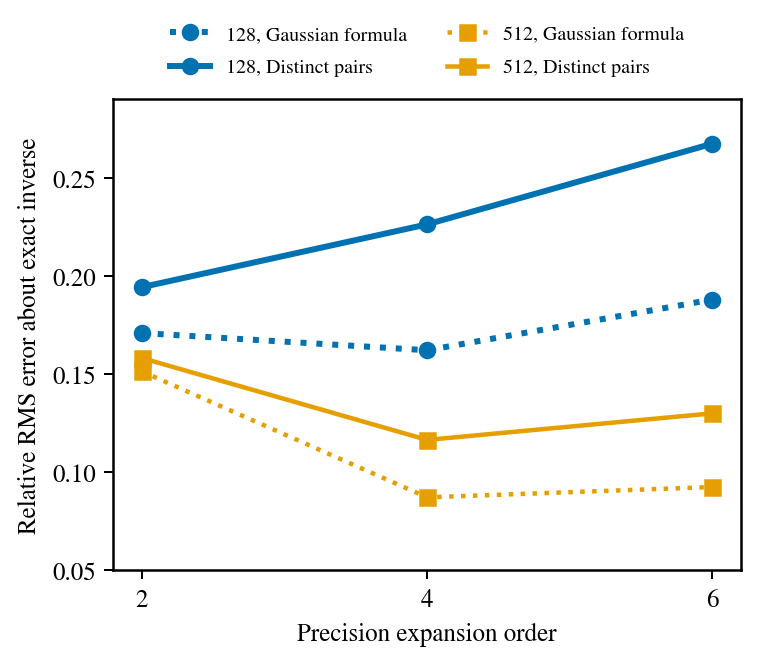

In [13]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/precision"

data = np.loadtxt(fname=folder / 'data.txt')
fig, ax = plt.subplots(figsize=(4.5, 3.4))
# The distinct-pair construction has no Gaussian-distribution assumption.
# Dotted companion curves deliberately apply Wishart formulas to these data.
colors = ['#0072B2', '#E69F00']
for group, count in enumerate((128,512)):
    for offset in (0,3):
        rows = data[(data[:,0] == count) & (data[:,1] >= offset)
                    & (data[:,1] < offset+3)]
        name = 'Gaussian formula' if offset == 0 else 'Distinct pairs'
        style = ':' if offset == 0 else '-'
        ax.plot([2,4,6], rows[:,4], color=colors[group],
                marker=['o','s'][group], linewidth=[2.4,1.8][group],
                linestyle=style, label=f'{count}, {name}')
ax.set_xticks(ticks=[2,4,6])
ax.set_xlabel('Precision expansion order')
ax.set_ylabel('Relative RMS error about exact inverse')
ax.set_ylim(bottom=.05, top=.29)
legend = ax.legend(loc='lower center', bbox_to_anchor=(.5,1.01),
                   ncol=2, fontsize=8, frameon=False)
fig.canvas.draw()
assert not legend.get_window_extent().overlaps(ax.get_window_extent())
NAME = 'precision.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


## Hold the analytical two-point block fixed

Write the joint covariance as

$$C=\begin{pmatrix}A&B\\ B^T&D\end{pmatrix}.$$

Here $A$ is the supplied two-point covariance, treated as exact. Simulations
inform $B$ and $D$. In the 480-row calculation the shapes are $400\times400$,
$400\times80$ and $80\times80$, respectively. Replacing the top-left block
after inverting an arbitrary matrix is not a consistent way to impose this.

Instead, describe the second observable conditionally on the first:

$$y=Hx+\epsilon,\qquad \operatorname{Cov}(\epsilon)=K^{-1}.$$

Multiplying out the covariance gives

$$B=AH^T,$$

$$D=K^{-1}+HAH^T.$$

The code below estimates the precision polynomial first, extracts $H$ and $K$,
and reconstructs these blocks. This keeps $A$ exactly. The polynomial estimator
and the final reconstructed covariance have different statistical properties:
the latter is nonlinear and is **not** asserted to be unbiased. A nonpositive
$K$ cannot describe a valid residual covariance and is reported rather than hidden.


In [14]:
"""Research precision expansion with a supplied, exact two-point block.

Distinct independent map pairs supply cross and three-point entries only.
The finite polynomial is unbiased for its deterministic polynomial target.
The final conditional reparameterization retains A exactly, but is nonlinear
and is NOT claimed to preserve finite-sample unbiasedness.
"""
import numpy as np


def estimates(vectors, reference, two_point_count):
    """Return second/fourth/sixth conditional precision and covariance pairs.

    reference must be fixed independently of vectors; its leading block is
    the exact supplied A. No Gaussian/Wishart sampling assumption is used.
    Odd final vectors are omitted from pairing, explicitly returned as used.
    """
    n = len(vectors)//2*2
    if n < 12:
        raise ValueError('Sixth order needs at least six independent pairs.')
    p = two_point_count
    dimension = vectors.shape[1]
    a = reference[:p, :p]
    factor = np.linalg.cholesky(reference)
    inverse = np.linalg.solve(factor, np.eye(dimension))
    # Pair differences remove the unknown mean. Dividing by sqrt(2)
    # restores the covariance of one draw, since two independent draws add.
    difference = (vectors[:n:2]-vectors[1:n:2])/np.sqrt(2.)
    # means[d] averages products of d DISTINCT pair factors. Descending
    # degree order prevents the current pair from appearing twice.
    means = [np.eye(dimension)] + [np.zeros_like(reference) for _ in range(6)]
    for count, row in enumerate(difference, 1):
        draw = np.outer(row, row)
        # This replacement is in physical coordinates, before whitening.
        # Every pair has the same exact A; no simulation estimates that block.
        draw[:p, :p] = a
        # Whitening expresses every entry in reference-covariance units.
        # The residual is I minus this dimensionless covariance draw.
        residual = np.eye(dimension)-inverse @ draw @ inverse.T
        for degree in range(min(count, 6), 0, -1):
            means[degree] = ((count-degree)/count*means[degree]
                            + degree/count*(means[degree-1] @ residual))
    results = []
    for order in (2, 4, 6):
        polynomial = sum(means[:order+1])
        raw = inverse.T @ ((polynomial+polynomial.T)/2) @ inverse
        k = raw[p:, p:]
        if np.linalg.eigvalsh(k)[0] <= 0:
            results.append((order, raw, None, None))
            continue
        # H predicts y from x, and K is the estimated residual precision.
        # Building the covariance from these two quantities keeps A exact.
        h = -np.linalg.solve(k, raw[p:, :p])
        conditional = np.linalg.solve(k, np.eye(dimension-p))
        covariance = np.block([[a, a @ h.T],
                               [h @ a, conditional+h @ a @ h.T]])
        precision = np.block([[np.linalg.solve(a, np.eye(p))+h.T @ k @ h,
                               -h.T @ k], [-k @ h, k]])
        np.testing.assert_array_equal(covariance[:p, :p], a)
        np.testing.assert_allclose((factor.T @ precision @ factor)
                                   @ (inverse @ covariance @ inverse.T), np.eye(dimension),
                                   atol=2.e-7, rtol=2.e-7)
        results.append((order, raw, precision, covariance))
    return results, n


### Check fixed block

Check fixed-A algebra on small matrices with exactly known covariance.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [15]:
def check_fixed_block():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    from pathlib import Path

    from itertools import combinations

    import numpy as np

    rng = np.random.default_rng(211126)

    truth = np.array([[1., .12, .08], [.12, .9, .10], [.08, .10, 1.1]])

    reference = np.diag([1., 1.2, 1.2])

    l = np.linalg.cholesky(reference)

    w = np.linalg.inv(l)

    a = truth[:1, :1]

    x = rng.multivariate_normal(np.zeros(3), truth, size=12)

    factors = []

    for delta in (x[::2]-x[1::2])/np.sqrt(2):
        z = np.outer(delta, delta)
        z[:1, :1] = a
        factors.append(np.eye(3)-w @ z @ w.T)

    expected = np.eye(3)

    results, used = estimates(x, reference, 1)

    for degree in range(1, 7):
        products = []
        for subset in combinations(range(6), degree):
            product = np.eye(3)
            for i in subset:
                product = product @ factors[i]
            products.append(product)
        term = np.mean(products, axis=0)
        expected += (term+term.T)/2
        if degree in (2, 4, 6):
            raw = results[(degree-2)//2][1]
            np.testing.assert_allclose(raw, w.T @ expected @ w, atol=2.e-12)

    print('Distinct-factor recurrence equals explicit products through sixth order.')

    b = [(row[:1, None] @ row[None, 1:]) for row in (x[::2]-x[1::2])/np.sqrt(2)]

    q = (sum(b).T @ sum(b)-sum(value.T @ value for value in b))/30

    brute = sum(b[i].T @ b[j] for i in range(6) for j in range(6) if i != j)/30

    np.testing.assert_allclose(q, brute, atol=1.e-14)

    print('Unbiased cross-square formula equals explicit distinct-pair sum.')

    t = np.eye(3)-w @ truth @ w.T

    targets = [w.T @ sum(np.linalg.matrix_power(t, k) for k in range(order+1)) @ w
               for order in (2, 4, 6)]

    values = []

    for repeat in range(512):
        draws = rng.multivariate_normal(np.zeros(3), truth, size=128)
        result, used = estimates(draws, reference, 1)
        values.append([item[1] for item in result])

    values = np.asarray(values)

    for index, order in enumerate((2, 4, 6)):
        error = values[:, index].std(axis=0, ddof=1)/np.sqrt(len(values))
        z = np.max(np.abs(values[:, index].mean(axis=0)-targets[index])/error)
        print('order', order, 'maximum mean discrepancy / Monte Carlo SE', z)
        assert z < 6

    print('Every returned constrained covariance retains A exactly and passes the inverse identity.')


# Run explicitly after checking the required inputs:
# check_fixed_block()


### Check full joint

Check the 480-dimensional ordering and a known finite-polynomial limit.

Zero input vectors are an algebraic test, not simulated observations. With
A held fixed, their masked factors have residual diag(0_400,I_80). Thus the
order-r constrained covariance must be diag(A,D_reference/(r+1)).

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [16]:
def check_full_joint():
    import os

    for name in ('OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
        os.environ[name] = '1'

    from pathlib import Path

    import numpy as np

    from astropy.io import fits

    p = PROJECT

    production = np.load(p / 'chains/gptg_ensemble_15000/des_y3_full_covariance.npz')

    rows = np.flatnonzero(production['rows'][:, 0] < 2)

    indices = (rows[:, None]*20+np.arange(20)).ravel()

    assert len(indices) == 400

    reference = np.zeros((480, 480))

    reference[:400, :400] = production['total'][np.ix_(indices, indices)]

    archived = fits.getdata(p / 'data/upstream_y3/data/covariance/xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits', extname='COVMAT')

    reference[400:, 400:] = archived[400:, 400:]

    result, used = estimates(np.zeros((12, 480)), reference, 400)

    for order, raw, precision, covariance in result:
        assert covariance is not None
        np.testing.assert_array_equal(covariance[:400, :400], reference[:400, :400])
        np.testing.assert_allclose(covariance[400:, 400:], reference[400:, 400:]/(order+1), rtol=1.e-10, atol=1.e-30)
        np.testing.assert_array_equal(covariance[:400, 400:], np.zeros((400, 80)))
        print('480 dimensions, order', order, ': exact A, zero cross block, D/(r+1) passed.')


# Run explicitly after checking the required inputs:
# check_full_joint()


### Analyze full joint

Full 480-entry fixed-A comparison, followed by 500-map validation.

The 400x400 A is production G+SSC+cNG and is never calibrated on these maps.
The starting 80x80 D is the archived, simulation-estimated published matrix,
fixed independently of these newly generated maps. B starts at zero. This
reference is not an analytical three-point covariance. No tuning on holdout.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [17]:
def analyze_full_joint(validate=False):
    import os

    for name in ('OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
        os.environ[name] = '1'

    from pathlib import Path

    import numpy as np

    from astropy.io import fits

    folder = PROJECT / 'chains/gptg_ensemble_15000'
    measurements = folder / 'full_joint_480'
    output = folder / 'full_joint_comparison'
    output.mkdir(exist_ok=True)
    # Row metadata identifies the xi-plus/minus blocks. Each block has
    # twenty angular bins; flattening these indices fixes the 400-row order.
    production = np.load(folder / 'des_y3_full_covariance.npz')
    rows = np.flatnonzero(production['rows'][:, 0] < 2)
    indices = (20*rows[:, None]+np.arange(20)).ravel()
    assert len(indices) == 400
    a = production['total'][np.ix_(indices, indices)]
    archived = fits.getdata(PROJECT / 'data/upstream_y3/data/covariance/xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits', extname='COVMAT')
    # A is the full analytical G+SSC+cNG block. The starting D comes from
    # the archived covariance; B starts at zero. Do not call all of this
    # reference analytical: only A has that origin in this calculation.
    reference = np.zeros((480, 480))
    reference[:400, :400] = a
    reference[400:, 400:] = archived[400:, 400:]
    # Cholesky writes reference = L L^T. Multiplication by L^{-1}
    # gives dimensionless coordinates for comparing precision weights.
    l = np.linalg.cholesky(reference)
    w = np.linalg.solve(l, np.eye(480))
    labels = ['direct', 'fixed_sample', 'order2', 'order4', 'order6']
    if not validate:
        vectors = np.array([np.loadtxt(measurements / f'map_{i:06d}.txt') for i in range(1000)])
        if vectors.shape != (1000, 480) or not np.isfinite(vectors).all():
            raise ValueError('Need 1000 completed 480-entry measurements.')
        sample = np.cov(vectors, rowvar=False, ddof=1)
        fixed_sample = sample.copy()
        fixed_sample[:400, :400] = a
        # Compare the same measured ensemble in every method. The direct
        # sample matrix is a comparator, not an exactly known truth.
        result, used = estimates(vectors, reference, 400)
        covariances = [sample, fixed_sample] + [item[3] for item in result]
        scales = np.sqrt(np.diag(sample))
        table = []
        for index, (label, covariance) in enumerate(zip(labels, covariances)):
            if covariance is None:
                table.append([index, np.nan, np.nan, np.nan, np.nan])
                continue
            white = w @ covariance @ w.T
            minimum = np.linalg.eigvalsh(white)[0]
            delta = (covariance-sample)/np.outer(scales, scales)
            table.append([index, minimum, np.max(np.abs(delta[:400, 400:])),
                          np.max(np.abs(delta[400:, 400:])),
                          np.max(np.abs(covariance[:400, :400]-a))])
            np.savetxt(output / f'covariance_{label}.txt', covariance)
            if minimum > 0:
                np.savetxt(output / f'precision_{label}_whitened.txt', np.linalg.solve(white, np.eye(480)))
        np.savetxt(output / 'reference.txt', reference)
        np.savetxt(output / 'comparison.txt', table,
                   header='method min_white_cov_eigenvalue max_normalized_B_difference max_normalized_D_difference max_A_change; '+','.join(labels))
        (output / 'FIRST1000_COMPLETE.txt').write_text('Full 480 dimensions; fixed reference; no validation used.\n')
        print('Full first-1000 comparison:', table, flush=True)
        return
    if not (output / 'FIRST1000_COMPLETE.txt').exists():
        raise ValueError('Freeze the first-1000 comparison before validating.')
    values = np.array([np.loadtxt(measurements / f'map_{i:06d}.txt') for i in range(1000, 1500)])
    if values.shape != (500, 480) or not np.isfinite(values).all():
        raise ValueError('Need 500 completed independent measurements.')
    # Holdout vectors are used only for scoring. No inverse of their
    # noisy covariance is needed: each quadratic form is evaluated directly.
    centered = (values-values.mean(axis=0)) @ w.T
    direct = np.loadtxt(output / 'precision_direct_whitened.txt')
    table = []
    for index, label in enumerate(labels):
        path = output / f'precision_{label}_whitened.txt'
        if not path.exists():
            table.append([index, np.nan, np.nan])
            continue
        precision = np.loadtxt(path)
        quadratic = np.einsum('ni,ij,nj->n', centered, precision-direct, centered)
        score = quadratic.sum()/499-np.linalg.slogdet(precision)[1]+np.linalg.slogdet(direct)[1]
        error = quadratic.std(ddof=1)/np.sqrt(500)*500/499
        table.append([index, score, error])
    np.savetxt(output / 'validation_scores.txt', table,
               header='method score_minus_direct approximate_SE; '+','.join(labels))
    print('Full 500-map independent validation:', table, flush=True)


# Run explicitly after checking the required inputs:
# analyze_full_joint(validate=False)


### Compare maps

Forward-test the initial GPTG generator with the same masked measurements.

The 32 supplied maps were also used for fitting. This is a diagnostic of
model mismatch, not an independent validation or a cosmological likelihood.
Generated maps are new random draws conditional on that fit. No map is
dropped according to its measured moments or covariance.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [18]:
def compare_maps():
    import os

    os.environ["OPENBLAS_NUM_THREADS"] = "1"

    os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

    os.environ["OMP_NUM_THREADS"] = "4"

    from pathlib import Path

    import numpy as np

    import ducc0

    import yaml

    from generate_maps import PROJECT, OUTPUT, setup, pseudo_modes, spectra

    """Compare pseudo-spectra, reconstructed PDF and sixteen raw moments."""
    record = yaml.safe_load((OUTPUT/'calibration.yaml').read_text())
    reference = np.load(file=OUTPUT/'fit_measurements.npz')
    generated = np.load(file=OUTPUT/'generated_measurements.npz')
    lmax = record['lmax']
    indices, geometry, ell, factor, nodes, weights = setup(lmax=lmax)
    centers = reference['centers'][:, 0].astype(int)
    spectrum = np.zeros((2, 4, 4, lmax+1))
    reconstructed = []
    paths = sorted((OUTPUT/'maps').glob('GPTG_DES_*.npy'))
    inverse = np.zeros_like(factor)
    inverse[ell >= 2] = 1./factor[ell >= 2]
    smooth = np.exp(-ell*(ell+1)*np.deg2rad(10./60.)**2/2.)
    for number, path in enumerate(paths):
        shear = np.load(
            file=path,
            mmap_mode='r',
        )
        modes = []
        proxy = []
        for source in range(4):
            result = pseudo_modes(
                shear=shear[source],
                indices=indices,
                geometry=geometry,
                lmax=lmax,
                workers=4,
                second_sign=record['second_component_sign_for_ducc'],
            )
            modes.append(result)
            convergence = ducc0.sht.synthesis(
                alm=result[:1]*inverse*smooth,
                spin=0,
                lmax=lmax,
                nthreads=4,
                **geometry,
            )
            proxy.append(convergence[0, centers])
        modes = np.asarray(modes)
        reconstructed.append(proxy)
        for i in range(4):
            for j in range(i, 4):
                for parity in range(2):
                    value = spectra(modes[i, parity], modes[j, parity], ell, lmax)
                    spectrum[parity, i, j] += value
                    if i != j:
                        spectrum[parity, j, i] += value
        print('compared', number+1, '/', len(paths), flush=True)
    spectrum /= len(paths)
    np.savez_compressed(
        OUTPUT/'forward_measurements.npz',
        pseudo_cl=spectrum,
        reconstruction=reconstructed,
    )
    target_vectors = np.concatenate([
        np.mean(reference['aperture']**2, axis=-1).reshape(-1, 8),
        np.mean(reference['aperture']**3, axis=-1).reshape(-1, 8),
    ], axis=1)
    new_vectors = np.concatenate([
        np.mean(generated['aperture']**2, axis=-1).reshape(-1, 8),
        np.mean(generated['aperture']**3, axis=-1).reshape(-1, 8),
    ], axis=1)
    covariance_real = np.cov(
        m=target_vectors,
        rowvar=False,
        ddof=1,
    )
    covariance_new = np.cov(
        m=new_vectors,
        rowvar=False,
        ddof=1,
    )
    mean_real = target_vectors.mean(axis=0)
    mean_new = new_vectors.mean(axis=0)
    # This normalization only describes the observed difference. The fit
    # couples model parameters to the reference sample, so these are not
    # independent significance tests or calibrated p-values.
    difference_error = np.sqrt(np.diag(covariance_real)/len(target_vectors)
                               + np.diag(covariance_new)/len(new_vectors))
    ratio = np.diag(covariance_new)/np.diag(covariance_real)
    scales_real = np.sqrt(np.diag(covariance_real))
    scales_new = np.sqrt(np.diag(covariance_new))
    correlation_real = covariance_real/scales_real[:, None]/scales_real[None, :]
    correlation_new = covariance_new/scales_new[:, None]/scales_new[None, :]
    np.savetxt(OUTPUT/'reference_vectors.txt', target_vectors)
    np.savetxt(OUTPUT/'reference_covariance.txt', covariance_real)
    np.savetxt(OUTPUT/'generated_covariance.txt', covariance_new)
    np.savetxt(OUTPUT/'mean_comparison.txt', np.column_stack([
        np.arange(16), mean_real, mean_new, difference_error,
        (mean_new-mean_real)/difference_error, ratio,
    ]), header='row reference_mean GPTG_mean descriptive_difference_SE difference_over_SE variance_ratio')
    band_edges = np.unique(np.geomspace(10, lmax+1, 18).astype(int))
    power_rows = []
    multipoles = np.arange(lmax+1)
    for lower, upper in zip(band_edges[:-1], band_edges[1:]):
        take = (multipoles >= lower) & (multipoles < upper)
        weight = 2*multipoles[take]+1
        for i in range(4):
            for j in range(i, 4):
                for parity in range(2):
                    old = np.average(
                        reference['pseudo_cl'][parity, i, j, take],
                        weights=weight,
                    )
                    new = np.average(spectrum[parity, i, j, take], weights=weight)
                    power_rows.append([lower, upper, i, j, parity, old, new])
    np.savetxt(OUTPUT/'power_comparison.txt', power_rows,
               header='ell_low ell_high bin_i bin_j parity_E0_B1 reference GPTG')
    probabilities = np.array([.01, .02, .05, .1, .25, .5, .75, .9, .95, .98, .99])
    quantile_rows = []
    for source in range(4):
        old = reference['reconstruction'][:, source].ravel()
        new = np.asarray(reconstructed)[:, source].ravel()
        for probability, old_q, new_q in zip(
                probabilities, np.quantile(
                    old,
                    probabilities,
                ), np.quantile(
                    new,
                    probabilities,
                )):
            quantile_rows.append([source, probability, old_q, new_q])
    np.savetxt(OUTPUT/'quantile_comparison.txt', quantile_rows,
               header='source probability reference_kappa_proxy GPTG_kappa_proxy')
    print('variance ratios', ratio, flush=True)
    print('maximum correlation difference',
          np.max(np.abs(correlation_new-correlation_real)), flush=True)
    print('mean difference / descriptive error',
          (mean_new-mean_real)/difference_error, flush=True)


# Run explicitly after checking the required inputs:
# compare_maps()


### Measure apertures

Measure raw and noise-corrected tomographic aperture moments for the pilot.

This calculation reuses saved aperture values; it never rereads all maps.
The noise correction follows the *assumed* independent Gaussian pixel model.
That model is known for our generated maps, but is only an approximation
for Rafael's archive. These are fixed-center, same-radius aperture moments,
not his published finite-triangle catalogue estimator.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [19]:
def measure_apertures():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '4'

    from itertools import combinations_with_replacement

    import numpy as np

    import yaml

    from generate_maps import OUTPUT, PROJECT, aperture_weights

    """Write explicit source-bin labels, moments and the filter noise variance.

    For each filter, independent pixel noise adds in quadrature: its
    variance is sigma_n**2 times the sum of squared component weights.
    Repeated source indices in a cubic product require one subtraction
    for each possible noise pair. Distinct source indices have zero noise
    cross-covariance in this initial model.
    """
    record = yaml.safe_load((OUTPUT / 'calibration.yaml').read_text())
    sigma = np.asarray(record['noise_sigma_per_component'])
    indices = np.load(file=PROJECT / 'maps_cov_512_v2/indices_512.npy')
    first, second, centers = aperture_weights(indices=indices)
    # Sparse multiplication squares each stored weight without making
    # a dense 128-by-369190 matrix. Sum over pixels, retaining centers.
    weight_square = first.multiply(first) + second.multiply(second)
    weight_square = np.asarray(weight_square.sum(axis=1)).ravel()
    weight_square = weight_square.reshape(2, 64)
    variance = sigma[:, None, None]**2 * weight_square[None, :, :]
    np.savetxt(
        fname=OUTPUT / 'aperture_noise_variance.txt',
        X=variance.reshape(8, 64),
        header='Rows source-major, radii 30/60 arcmin; columns 64 centers.',
    )
    labels = []
    triples = list(combinations_with_replacement(range(4), 3))
    pairs = list(combinations_with_replacement(range(4), 2))
    for radius in (30, 60):
        for i, j in pairs:
            labels.append(f'2 {radius} {i+1} {j+1} 0')
        for i, j, k in triples:
            labels.append(f'3 {radius} {i+1} {j+1} {k+1}')
    (OUTPUT / 'tomographic_rows.txt').write_text(
        '# order radius_arcmin source_i source_j source_k (0 unused)\n'
        + '\n'.join(labels) + '\n',
    )
    for name, filename in (
        ('reference', 'fit_measurements.npz'),
        ('generated', 'generated_measurements.npz'),
    ):
        data = np.load(file=OUTPUT / filename)
        aperture = data['aperture']  # [map, source, radius, center]
        raw = []
        corrected = []
        for radius in range(2):
            for i, j in pairs:
                value = aperture[:, i, radius] * aperture[:, j, radius]
                noise_pair = np.zeros(64)
                if i == j:
                    noise_pair = variance[i, radius]
                raw.append(value.mean(axis=-1))
                corrected.append((value-noise_pair).mean(axis=-1))
            for i, j, k in triples:
                ai = aperture[:, i, radius]
                aj = aperture[:, j, radius]
                ak = aperture[:, k, radius]
                value = ai * aj * ak
                # E[A_i A_j A_k | signal] contains three possible
                # noise pairings. Each remaining factor is estimated
                # by its observed aperture, which has the correct mean.
                subtraction = np.zeros_like(value)
                if i == j:
                    subtraction += variance[i, radius] * ak
                if i == k:
                    subtraction += variance[i, radius] * aj
                if j == k:
                    subtraction += variance[j, radius] * ai
                raw.append(value.mean(axis=-1))
                corrected.append((value-subtraction).mean(axis=-1))
        raw = np.asarray(raw).T
        corrected = np.asarray(corrected).T
        np.savetxt(
            fname=OUTPUT / f'{name}_tomographic_raw.txt',
            X=raw,
        )
        np.savetxt(
            fname=OUTPUT / f'{name}_tomographic_corrected.txt',
            X=corrected,
        )
        print(name, raw.shape, 'raw/corrected second and third moments')
    print('Correction uses the stated pixel-noise model, not fitted moments.')


# Run explicitly after checking the required inputs:
# measure_apertures()


### Map precision tests

Test precision algebra on a fixed empirical population of GPTG measurements.

These are independent resampling experiments CONDITIONAL on a frozen list
of 64 measured map vectors. Their true discrete-population covariance is
known exactly. Resampling is not additional physical skies, and this test
does not establish that GPTG has the same covariance as Rafael's simulations.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [20]:
def map_precision_tests():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '1'

    from pathlib import Path

    import sys

    import numpy as np

    sys.path.insert(0, str(PROJECT/'notes/covariance_from_simulations'))

    from precision_order_tests import coefficients, gaussian_orders, distinct_orders, targets, summarize

    """Use all 64 population members, with replacement, in each experiment."""
    population = np.loadtxt(
        fname=PROJECT/'tests/gptg_pilot/measurement_population.txt',
    )[:, [0, 6, 8, 14]]
    # Two squared and two cubed aperture moments retain a joint cross block.
    # Fixed unit conversion keeps tiny lensing units from obscuring the algebra.
    population = (population-population.mean(axis=0))/population.std(axis=0)
    truth = population.T @ population / len(population)
    # Denominator 64 is deliberate: the list IS the stipulated population,
    # not an unbiased estimate of an unknown continuous population covariance.
    model = 2.*truth + .1*np.eye(4)
    inverse = np.linalg.solve(
        a=np.linalg.cholesky(model),
        b=np.eye(4),
    )
    white_population = population @ inverse.T
    order_targets, exact = targets(covariance=inverse@truth@inverse.T)
    all_targets = np.concatenate([order_targets, order_targets])
    output = PROJECT/'chains/covariance_sixth_order'
    output.mkdir(
        exist_ok=True,
        parents=True,
    )
    rows = []
    for sample_count in (128, 512):
        weights = coefficients(degrees_of_freedom=sample_count-1)
        rng = np.random.default_rng(seed=618274)
        batches = []
        for start in range(0, 8192, 256):
            indices = rng.integers(
                low=0,
                high=len(population),
                size=(256, sample_count),
            )
            white = white_population[indices]
            centered = white-white.mean(
                axis=1,
                keepdims=True,
            )
            sample = centered.swapaxes(-1, -2)@centered/(sample_count-1)
            batches.append(np.concatenate([
                gaussian_orders(
                    sample=sample,
                    weights=weights,
                ),
                distinct_orders(vectors=white),
            ]))
        estimates = np.concatenate(batches, axis=1)
        summary = summarize(
            estimates=estimates,
            truth=all_targets,
            exact=exact,
        )
        print('sample_count', sample_count, 'Wishart2,4,6; distinct2,4,6\n',
              summary, flush=True)
        for method, row in enumerate(summary):
            rows.append([sample_count, method, *row])
    np.savetxt(
        fname=output/'gptg_empirical_summary.txt',
        X=rows,
        header=('sample_count method max_bias_over_MCSE relative_RMS_truncated '
                'relative_RMS_exact nonpositive_fraction bias00 MCSE00; '
                '8192 independent resamplings of a fixed 64-member population; '
                'NOT new independent N-body or full-sky maps'),
    )


# Run explicitly after checking the required inputs:
# map_precision_tests()


### Check numerics

Check the map transform and sixth-order algebra without a large simulation run.

The checks isolate deterministic numerical operations from the uncertain
physical calibration: Hermite correlation integrals, harmonic conventions,
noise subtraction, and products of distinct random factors. They do not
establish agreement with a DES catalogue estimator or N-body covariance.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [21]:
def check_numerics():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '4'

    from itertools import combinations

    import sys

    import ducc0

    import numpy as np

    from scipy.special import roots_hermitenorm

    import yaml

    from generate_maps import PROJECT, OUTPUT, normalized_transform, harmonic_indices

    sys.path.insert(0, str(PROJECT / 'notes/covariance_from_simulations'))

    from precision_order_tests import distinct_orders

    """Print measured residuals and stop if a numerical identity fails."""
    record = yaml.safe_load((OUTPUT / 'calibration.yaml').read_text())
    parameters = np.asarray(record['point_parameters_a1_a2_b_x0_t'])
    nodes, weights = roots_hermitenorm(n=160)
    weights /= np.sqrt(2*np.pi)
    fine_nodes, fine_weights = roots_hermitenorm(n=240)
    fine_weights /= np.sqrt(2*np.pi)
    basis = np.ones((97, len(nodes)))
    basis[1] = nodes
    for degree in range(1, 96):
        basis[degree+1] = (
            nodes*basis[degree] - np.sqrt(degree)*basis[degree-1]
        ) / np.sqrt(degree+1)
    coefficients = []
    normalization_change = 0.
    for values in parameters:
        coarse = normalized_transform(
            gaussian=nodes,
            parameters=values,
            nodes=nodes,
            weights=weights,
        )
        fine = normalized_transform(
            gaussian=nodes,
            parameters=values,
            nodes=fine_nodes,
            weights=fine_weights,
        )
        # Weighted RMS measures the difference over Gaussian probability,
        # rather than making a negligible far-tail value set the scale.
        change = np.sqrt(weights @ (coarse-fine)**2)
        normalization_change = max(normalization_change, change)
        coefficients.append(basis @ (weights*coarse))
    coefficients = np.asarray(coefficients)
    integration_error = 0.
    truncation_error = 0.
    for i in range(4):
        first = normalized_transform(
            gaussian=nodes,
            parameters=parameters[i],
            nodes=nodes,
            weights=weights,
        )
        for j in range(i, 4):
            for rho in (-0.8, 0., 0.5, 0.95):
                # Conditional construction converts the correlated 2D
                # Gaussian integral to a product quadrature in two IID axes.
                second_input = rho*nodes[:, None]
                second_input = second_input + np.sqrt(1-rho*rho)*nodes[None, :]
                second = normalized_transform(
                    gaussian=second_input,
                    parameters=parameters[j],
                    nodes=nodes,
                    weights=weights,
                )
                direct = (weights*first) @ second @ weights
                series = coefficients[i]*coefficients[j]
                series[0] = 0.
                coarse = np.polynomial.polynomial.polyval(rho, series[:65])
                fine = np.polynomial.polynomial.polyval(rho, series)
                integration_error = max(integration_error, abs(coarse-direct))
                truncation_error = max(truncation_error, abs(coarse-fine))
    assert normalization_change < 1.e-5
    assert integration_error < 1.e-5
    assert truncation_error < 1.e-5
    print('Normalization 160 -> 240 nodes, weighted RMS:', normalization_change)
    print('Hermite 64 versus direct 2D quadrature:', integration_error)
    print('Hermite 64 -> 96, maximum correlation change:', truncation_error)

    # A low-resolution band-limited sky isolates transform conventions.
    # Here there is no nonlinear high-ell signal for a finite projection
    # to discard, so the harmonic coefficients should round-trip.
    lmax = 24
    ell = harmonic_indices(lmax=lmax)
    rng = np.random.default_rng(seed=114759)
    alm = rng.normal(size=(1, len(ell))).astype(complex)
    alm += 1j*rng.normal(size=alm.shape)
    alm[:, :lmax+1] = alm[:, :lmax+1].real
    alm[:, ell < 2] = 0.
    geometry = ducc0.healpix.Healpix_Base(32, 'RING').sht_info()
    sky = ducc0.sht.synthesis(
        alm=alm,
        spin=0,
        lmax=lmax,
        nthreads=4,
        **geometry,
    )
    recovered = ducc0.sht.pseudo_analysis(
        map=sky,
        spin=0,
        lmax=lmax,
        maxiter=30,
        epsilon=1.e-10,
        nthreads=4,
        **geometry,
    )[0]
    roundtrip = np.linalg.norm(recovered-alm) / np.linalg.norm(alm)
    assert roundtrip < 1.e-8
    print('Band-limited scalar harmonic round trip:', roundtrip)

    # Enumerating all subsets is cheap for seven pairs. Factors deliberately
    # do not commute, so a scalar-only check would not test their order.
    vectors = rng.normal(size=(1, 14, 3))
    pair = (vectors[0, 0::2]-vectors[0, 1::2]) / np.sqrt(2.)
    factors = np.eye(3)-pair[:, :, None]*pair[:, None, :]
    terms = [np.eye(3)]
    for degree in range(1, 7):
        products = []
        for subset in combinations(range(7), degree):
            product = np.eye(3)
            for index in subset:
                product = product @ factors[index]
            products.append(product)
        terms.append(np.mean(
            a=products,
            axis=0,
        ))
    expected = []
    for order in (2, 4, 6):
        value = sum(terms[:order+1])
        expected.append((value+value.T)/2.)
    actual = distinct_orders(vectors=vectors)[:, 0]
    np.testing.assert_allclose(
        actual,
        expected,
        rtol=1.e-12,
        atol=1.e-12,
    )
    print('Distinct-pair recurrence agrees with every subset through degree 6.')

    # Gaussian quadrature integrates these low-degree polynomials exactly.
    # No Monte Carlo fluctuation can hide an incorrect coefficient of 3.
    signal = .2
    noise_variance = .07
    observed = signal + np.sqrt(noise_variance)*nodes
    second = weights @ (observed**2-noise_variance)
    third = weights @ (observed**3-3*noise_variance*observed)
    np.testing.assert_allclose(second, signal**2, atol=1.e-14)
    np.testing.assert_allclose(third, signal**3, atol=1.e-14)
    print('Noise-subtracted square and cube recover', second, third)


# Run explicitly after checking the required inputs:
# check_numerics()


### Check map storage

Measure float32 storage error using all 64 saved float64 pilot maps.

Generation and aperture accumulation stay in float64. Only the saved shear
values are rounded to float32 and then decoded to float64, isolating storage
precision from arithmetic precision. Original maps are never modified.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [22]:
def check_map_storage():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '4'

    import numpy as np

    from generate_maps import OUTPUT, PROJECT, aperture_weights

    """Compare raw moments, covariance and precision on the same realizations."""
    indices = np.load(file=PROJECT / 'maps_cov_512_v2/indices_512.npy')
    first, second, centers = aperture_weights(indices=indices)
    paths = sorted((OUTPUT / 'maps').glob('GPTG_DES_*.npy'))
    if len(paths) != 64:
        raise ValueError(f'Expected the 64-map pilot, found {len(paths)} maps.')
    original_vectors = []
    rounded_vectors = []
    maximum_shear_error = 0.
    for path in paths:
        original = np.load(
            file=path,
            mmap_mode='r',
        )
        if original.dtype != np.float64:
            raise ValueError(f'The storage reference must remain float64: {path}')
        # This is the full write/read rounding operation. Casting back to
        # float64 cannot recover lost digits, but lets subsequent arithmetic
        # use the same precision and summation path as the reference.
        rounded = original.astype(np.float32).astype(np.float64)
        maximum_shear_error = max(
            maximum_shear_error,
            np.max(np.abs(rounded-original)),
        )
        for shear, collection in (
            (original, original_vectors),
            (rounded, rounded_vectors),
        ):
            values = first @ shear[:, 0].T + second @ shear[:, 1].T
            values = values.T.reshape(4, 2, 64)
            collection.append(np.concatenate([
                (values**2).mean(axis=2).ravel(),
                (values**3).mean(axis=2).ravel(),
            ]))
    original_vectors = np.asarray(original_vectors)
    rounded_vectors = np.asarray(rounded_vectors)
    covariance = np.cov(
        m=original_vectors,
        rowvar=False,
        ddof=1,
    )
    rounded_covariance = np.cov(
        m=rounded_vectors,
        rowvar=False,
        ddof=1,
    )
    scale = np.sqrt(np.diag(covariance))
    difference = rounded_vectors-original_vectors
    inverse = np.linalg.solve(
        a=np.linalg.cholesky(covariance),
        b=np.eye(16),
    )
    white_difference = difference @ inverse.T
    matrix_change = inverse @ (rounded_covariance-covariance) @ inverse.T
    matrix_eigenvalues = np.linalg.eigvalsh(matrix_change)
    # Relative precision eigenvalues are 1/(1+lambda) in the covariance's
    # own coordinates. This checks all directions, including weak ones.
    inverse_change = 1./(1.+matrix_eigenvalues)-1.
    results = np.array([
        maximum_shear_error,
        np.max(np.abs(difference/scale)),
        np.max(np.linalg.norm(white_difference, axis=1)),
        np.max(np.abs(np.diag(rounded_covariance)/np.diag(covariance)-1.)),
        np.max(np.abs(matrix_eigenvalues)),
        np.max(np.abs(inverse_change)),
    ])
    labels = [
        'max_absolute_shear_rounding',
        'max_moment_change_in_its_single_map_standard_deviation',
        'max_joint_covariance_weighted_vector_change',
        'max_fractional_variance_change',
        'max_relative_covariance_eigendirection_change',
        'max_relative_precision_eigendirection_change',
    ]
    output = OUTPUT / 'float32_storage_check.txt'
    output.write_text('\n'.join(f'{label} {value:.17e}'
                                for label, value in zip(labels, results))+'\n')
    np.savetxt(
        fname=OUTPUT / 'float32_moment_differences.txt',
        X=difference,
        header='64 maps x 16 raw aperture moments; float32 decoded to float64 minus float64',
    )
    print(output.read_text(), end='')
    print('No per-row relative cubic errors: cubes near zero make that ratio misleading.')


# Run explicitly after checking the required inputs:
# check_map_storage()


## Compare the full covariance blocks visually

After `analyze_full_joint()` has written its matrices, the function below shows two different comparisons. The split triangle places each method’s correlation coefficients on one side. The difference plot divides both matrices by the *same* direct-sample standard deviations: its colors are differences in common units, not percentage errors relative to truth.

The boundary after row 400 separates the fixed analytical two-point block from the 80 third-order entries. A visible difference in the upper-left block is expected when comparing the fixed analytical block to the fully sample-estimated matrix. It does not mean that the correction changed the supplied analytical block.


In [23]:
def plot_full_joint(method="order2"):
    # These are small 480-by-480 text matrices, not the large shear maps.
    folder = PROJECT / "chains/gptg_ensemble_15000/full_joint_comparison"
    direct = np.loadtxt(folder / "covariance_direct.txt")
    corrected = np.loadtxt(folder / f"covariance_{method}.txt")

    # Standard deviation is the square root of variance (the diagonal).
    # An outer product supplies the units of every covariance entry C_ij.
    direct_sigma = np.sqrt(np.diag(direct))
    corrected_sigma = np.sqrt(np.diag(corrected))
    direct_units = np.outer(direct_sigma, direct_sigma)
    corrected_units = np.outer(corrected_sigma, corrected_sigma)
    direct_correlation = direct / direct_units
    corrected_correlation = corrected / corrected_units

    # Correlations are symmetric. Use one triangle for each method so that
    # matching structures can be compared without switching between panels.
    lower = np.tril(np.ones(direct.shape, dtype=bool))
    split = np.where(lower, direct_correlation, corrected_correlation)
    difference = (corrected - direct) / direct_units
    limit = max(float(np.max(np.abs(difference))), 1.e-15)
    fig, axes = plt.subplots(ncols=2, figsize=(11, 4.6))
    left = axes[0].imshow(split, vmin=-1, vmax=1, cmap="RdBu_r")
    right = axes[1].imshow(difference, vmin=-limit, vmax=limit, cmap="RdBu_r")
    axes[0].set_title(f"Lower: direct; upper: {method}")
    axes[1].set_title("Corrected minus direct / common standard deviations")
    for ax in axes:
        ax.axhline(399.5, color="black", linewidth=0.7)
        ax.axvline(399.5, color="black", linewidth=0.7)
        ax.set_xlabel("Data-vector row")
        ax.set_ylabel("Data-vector row")
    fig.colorbar(left, ax=axes[0], label="Correlation")
    fig.colorbar(right, ax=axes[1], label="Normalized covariance difference")
    fig.tight_layout()
    fig.savefig(folder / f"comparison_{method}.pdf")
    plt.show()

# Call only after the corresponding covariance has been produced:
# plot_full_joint(method="order2")
